# **Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Feature-Specific Outlier Capping & Selected Log Transformations**

1. Separate features and target, excluding customer ID and raw date columns. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Apply selected log transformations to reduce feature skewness:
   - log1p(x) for positive or zero-valued features.
   - sign(x) × log1p(|x|) for features containing negative values.
5. Validate that features selected for log1p do not contain negative values.
6. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
7. Create custom OutlierCapper and LogTransformer transformers to apply transformations within the pipeline and prevent data leakage during cross-validation.
8. Impute numerical missing values using the median. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
9. Handle class imbalance using class_weight='balanced' in Random Forest.
10. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
11. Display the best hyperparameters and top 10 hyperparameter combinations.
12. Compare feature skewness before and after log transformations to assess skewness reduction.
13. Generate validation probabilities and perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals).
14. Select the threshold with the highest validation F1 Score.
15. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
16. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
17. Analyse and visualize the top 20 feature importances.
18. Display the best CV PR-AUC, selected threshold, test PR-AUC, test F1 Score, and number of transformed features.

this experiment incorporates changes to the original Exp 11(2) model based on Log Transformations   
Exp 12(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp12

## 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. EXPERIMENT CONFIGURATION

In [3]:
EXPERIMENT_NAME = "Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Median Imputation | Log Transformations (104 Features)"
RANDOM_STATE = 42

date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

# Positive / zero features: log1p(x)
log1p_features = [
    'tenure_margin_interaction',
    'forecast_cons_12m',
    'forecast_cons_year',
    'cons_12m',
    'cons_last_month',
    'cons_gas_12m',
    'consumption_per_power',
    'margin_per_power',
    'margin_net_pow_ele',
    'forecast_meter_rent_12m',
    'imp_cons',
    'discount_consumption_interaction',
    'margin_per_product'
]

# Features containing negative values: sign(x) * log(1 + abs(x))
signed_log1p_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure',
    'price_power_interaction',
    'dec_jan_off_peak_fix_diff'
]

## 2. PREPARE FEATURES AND TARGET

In [4]:
drop_cols = ['id', 'churn'] + [
    col for col in date_cols if col in df.columns
]

X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("=" * 75)
print(EXPERIMENT_NAME)
print("=" * 75)
print("Dataset Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Median Imputation | Log Transformations (104 Features)
Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 3. TRAIN / VALIDATION / TEST SPLITS

In [5]:
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("\nSplit Sizes:")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Split Sizes:
Model Training: (9347, 104)
Validation: (2337, 104)
Test: (2922, 104)


## 4. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

log1p_features = [
    col for col in log1p_features if col in numerical_cols
]
signed_log1p_features = [
    col for col in signed_log1p_features if col in numerical_cols
]

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))
print("\nLog1p Features:")
print(log1p_features)
print("\nSigned Log1p Features:")
print(signed_log1p_features)


Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101

Log1p Features:
['tenure_margin_interaction', 'forecast_cons_12m', 'forecast_cons_year', 'cons_12m', 'cons_last_month', 'cons_gas_12m', 'consumption_per_power', 'margin_per_power', 'margin_net_pow_ele', 'forecast_meter_rent_12m', 'imp_cons', 'discount_consumption_interaction', 'margin_per_product']

Signed Log1p Features:
['cons_last_month_diff', 'forecast_cons_diff', 'price_consumption_exposure', 'price_power_interaction', 'dec_jan_off_peak_fix_diff']


## 5. VALIDATE LOG1P FEATURES

In [7]:
# log1p(x) requires x >= 0.
invalid_log_features = [
    col for col in log1p_features
    if (X_model_train[col].dropna() < 0).any()
]

if invalid_log_features:
    raise ValueError(
        "These log1p features contain negative values. "
        "Review their transformation before proceeding: "
        f"{invalid_log_features}"
    )

## 6. OUTLIER CAPPING CONFIGURATION

In [8]:
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

## 7. OUTLIER CAPPING TRANSFORMER

In [9]:
# Quantile limits are learned independently within each CV training fold.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}

        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }

        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }

        return self

    def transform(self, X):
        X = X.copy()

        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])

        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

## 8. LOG TRANSFORMATION TRANSFORMER

In [10]:
class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, positive_features=None, signed_features=None):
        self.positive_features = positive_features
        self.signed_features = signed_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.positive_features or []:
            X[col] = np.log1p(X[col])

        for col in self.signed_features or []:
            X[col] = np.sign(X[col]) * np.log1p(np.abs(X[col]))

        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

## 9. PREPROCESSING PIPELINE

In [11]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numerical_pipeline, numerical_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

## 10. RANDOM FOREST PIPELINE

In [12]:
rf_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('log_transform', LogTransformer(
        positive_features=log1p_features,
        signed_features=signed_log1p_features
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

## 11. STRATIFIED CROSS VALIDATION

In [13]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

## 12. HYPERPARAMETER SEARCH SPACE

In [14]:
param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [None, 10, 15, 20],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.3, 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

## 13. RANDOMIZED SEARCH CV

In [15]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 14. FIT RANDOMIZED SEARCH

In [16]:
# Raw training data is passed; capping, log transformations and imputation
# are fitted independently inside each CV fold.
random_search.fit(X_model_train, y_model_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__class_weight': ['balanced', 'balanced_subsample'], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [2, 5, ...], ...}"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 15. BEST HYPERPARAMETERS

In [17]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 700, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 20, 'model__class_weight': 'balanced_subsample'}

Best CV PR-AUC: 0.2683


## 16. BEST RANDOM FOREST MODEL

In [18]:
best_rf_pipeline = random_search.best_estimator_

## 17. RANDOMIZED SEARCH RESULTS

In [19]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__class_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features param_model__class_weight  mean_train_score  mean_test_score  std_test_score
                       700                     20                              10                              5                       0.5        balanced_subsample            0.9997           0.2683          0.0222
                       300                   None                               5                              5                       0.5        balanced_subsample            0.9996           0.2659          0.0222
                       500                     20                              20                             15                       0.5        balanced_subsample            0.9361           0.2558          0.0221
                       500                     20                               5         

## 18. OUTLIER CAPPING AND LOG TRANSFORMATION SUMMARY

In [20]:
# Use the fitted preprocessing steps on model-training data for diagnostics.
fitted_capper = best_rf_pipeline.named_steps['outlier_capping']
fitted_log_transformer = best_rf_pipeline.named_steps['log_transform']

X_train_capped = fitted_capper.transform(X_model_train)
X_train_transformed = fitted_log_transformer.transform(X_train_capped)

cap_summary = []

for col, limits in fitted_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_train_capped[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured outlier features were found.")


==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -19883.990    449656.000  108516.213   -19883.990   108516.213
        forecast_cons_diff  -6207018.990 -3114341.674      1690.100     -26.706 -3114341.674      -26.706
price_consumption_exposure  -1563821.153  -100136.355    481476.438    7581.672  -100136.355     7581.672
     consumption_per_power         0.000        0.000    590028.897  186563.330          NaN   186563.330
                  cons_12m         0.000        0.000   6207104.000 3118110.000          NaN  3118110.000
           cons_last_month         0.000        0.000    771203.000  382647.000          NaN   382647.000
                   pow_max         3.300        3.300       320.000      77.108          NaN       77.108
        forecast_cons_year         0.000        0.000    175375.000   11417.160          NaN    11417.160
           

## 19. SKEWNESS COMPARISON

In [21]:
skewness_rows = []

for col in log1p_features:
    before = X_train_capped[col].dropna()
    after = X_train_transformed[col].dropna()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'log1p(x)',
        'Skew_Before': before.skew(),
        'Skew_After': after.skew(),
        'Absolute_Skew_Reduction': abs(before.skew()) - abs(after.skew())
    })

for col in signed_log1p_features:
    before = X_train_capped[col].dropna()
    after = X_train_transformed[col].dropna()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'signed_log1p(x)',
        'Skew_Before': before.skew(),
        'Skew_After': after.skew(),
        'Absolute_Skew_Reduction': abs(before.skew()) - abs(after.skew())
    })

skewness_comparison_df = pd.DataFrame(skewness_rows)

if not skewness_comparison_df.empty:
    skewness_comparison_df = skewness_comparison_df.sort_values(
        'Absolute_Skew_Reduction', ascending=False
    )
    print("\n==== SKEWNESS COMPARISON ====")
    print(skewness_comparison_df.round(4).to_string(index=False))


==== SKEWNESS COMPARISON ====
                         Feature  Transformation  Skew_Before  Skew_After  Absolute_Skew_Reduction
       tenure_margin_interaction        log1p(x)      24.8727     -1.4695                  23.4033
discount_consumption_interaction        log1p(x)      17.5147      5.2231                  12.2915
                    cons_gas_12m        log1p(x)      10.4534      1.8672                   8.5862
               forecast_cons_12m        log1p(x)       8.1885     -2.0126                   6.1760
                margin_per_power        log1p(x)       6.0096     -0.1087                   5.9010
            cons_last_month_diff signed_log1p(x)       5.4381      0.3070                   5.1311
                 cons_last_month        log1p(x)       5.2255     -0.2086                   5.0170
         price_power_interaction signed_log1p(x)      -4.6406     -0.0888                   4.5517
       dec_jan_off_peak_fix_diff signed_log1p(x)      -6.1463      1.5975     

## 20. VALIDATION PROBABILITIES

In [22]:
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

## 21. PRECISION-RECALL CURVE

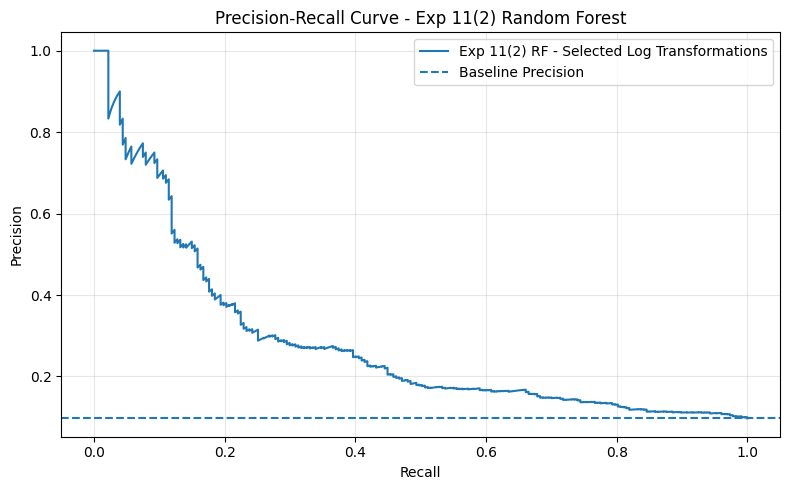

In [23]:
precision_curve, recall_curve, _ = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 11(2) RF - Selected Log Transformations'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 11(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 22. THRESHOLD ANALYSIS ON VALIDATION DATA


==== THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1021  0.9824    0.1850
      0.06     0.1045  0.9780    0.1889
      0.07     0.1072  0.9692    0.1931
      0.08     0.1096  0.9515    0.1966
      0.09     0.1115  0.9207    0.1990
      0.10     0.1134  0.8855    0.2011
      0.11     0.1146  0.8458    0.2018
      0.12     0.1192  0.8194    0.2082
      0.13     0.1267  0.8018    0.2189
      0.14     0.1339  0.7841    0.2288
      0.15     0.1390  0.7445    0.2342
      0.16     0.1455  0.7181    0.2420
      0.17     0.1492  0.6828    0.2449
      0.18     0.1583  0.6652    0.2557
      0.19     0.1649  0.6344    0.2618
      0.20     0.1703  0.5903    0.2643
      0.21     0.1717  0.5463    0.2613
      0.22     0.1775  0.5066    0.2629
      0.23     0.1861  0.4846    0.2689
      0.24     0.1978  0.4670    0.2779
      0.25     0.2086  0.4493    0.2849
      0.26     0.2260  0.4449    0.2997
      0.27     0.2328  0.4185    0.2992
      0.28

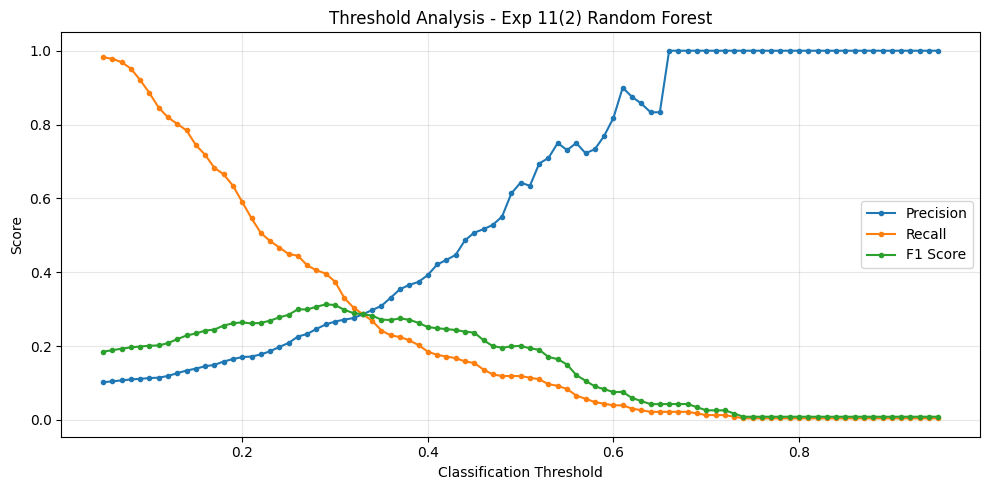

In [24]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

best_threshold_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_threshold_row['Threshold'])

print("\n==== THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))
print("\n==== BEST VALIDATION THRESHOLD ====")
print(best_threshold_row)

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 11(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 23. PREDICTIONS

In [25]:
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

## 24. EVALUATION FUNCTION

In [26]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(
    y_model_train, y_pred_train, y_prob_train
)
validation_metrics = calculate_metrics(
    y_val, y_pred_val, y_prob_val
)
test_metrics = calculate_metrics(
    y_test, y_pred_test, y_prob_test
)

## 25. PRINT METRICS

In [27]:
def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)


==== TRAIN METRICS ====
Accuracy    : 0.9661
Precision   : 0.7412
Recall      : 1.0000
F1 Score    : 0.8514
ROC-AUC     : 1.0000
PR-AUC      : 0.9997

==== VALIDATION METRICS ====
Accuracy    : 0.8310
Precision   : 0.2586
Recall      : 0.3965
F1 Score    : 0.3130
ROC-AUC     : 0.6941
PR-AUC      : 0.2845

==== TEST METRICS ====
Accuracy    : 0.8354
Precision   : 0.2704
Recall      : 0.4085
F1 Score    : 0.3254
ROC-AUC     : 0.6943
PR-AUC      : 0.3223


## 26. TEST CONFUSION MATRIX

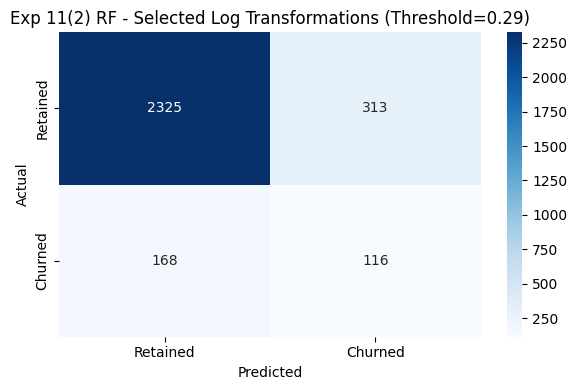

In [28]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Exp 11(2) RF - Selected Log Transformations '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

## 27. TEST CLASSIFICATION REPORT

In [29]:
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.88      0.91      2638
     Churned       0.27      0.41      0.33       284

    accuracy                           0.84      2922
   macro avg       0.60      0.64      0.62      2922
weighted avg       0.87      0.84      0.85      2922



## 28. FEATURE IMPORTANCE

In [30]:
fitted_preprocessor = best_rf_pipeline.named_steps['preprocessing']
rf_fitted = best_rf_pipeline.named_steps['model']
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    by='Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))


==== TOP 20 FEATURE IMPORTANCES ====
                   Feature  Importance
        margin_net_pow_ele     0.06997
   forecast_meter_rent_12m     0.03878
      cons_last_month_diff     0.03122
       forecast_cons_ratio     0.02932
    margin_per_consumption     0.02803
     consumption_per_power     0.02372
   price_power_interaction     0.02371
          margin_per_power     0.02364
              months_activ     0.02325
price_consumption_exposure     0.02257
                   pow_max     0.02099
         months_modif_prod     0.02093
     cons_last_month_ratio     0.02043
        forecast_cons_diff     0.01894
        margin_per_product     0.01891
                  cons_12m     0.01770
   var_year_price_off_peak     0.01739
         forecast_cons_12m     0.01723
           cons_last_month     0.01658
            price_off_peak     0.01591


## 29. FEATURE IMPORTANCE VISUALIZATION

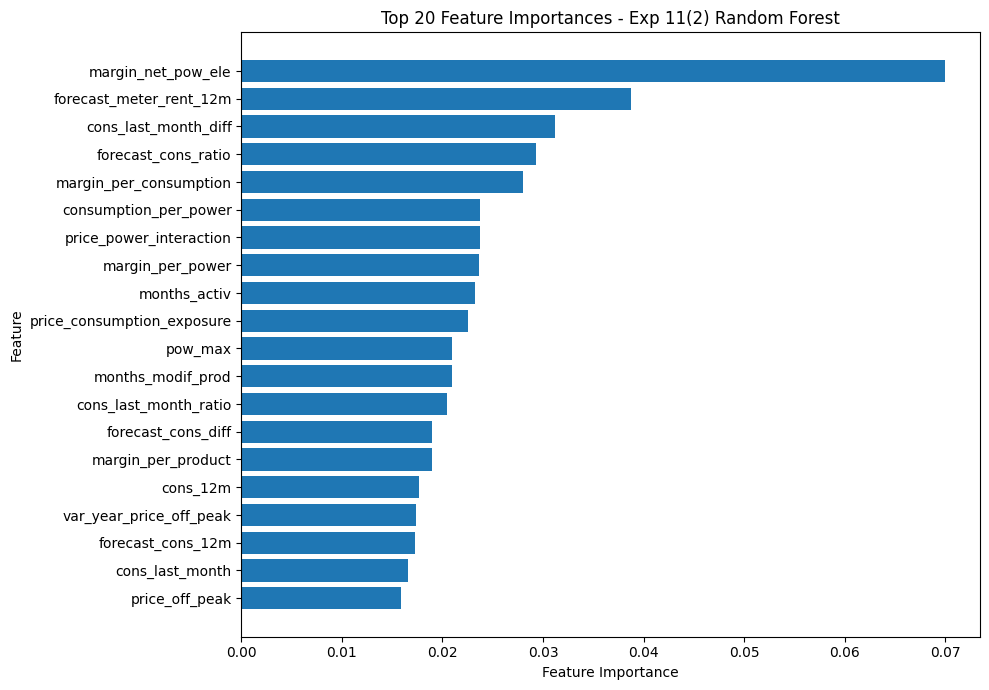

In [31]:
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 11(2) Random Forest')
plt.tight_layout()
plt.show()

## 30. FINAL EXPERIMENT SUMMARY

In [32]:
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp11_2_RF_Log_Transformations']
)

print("\n" + "=" * 75)
print("EXP 11(2) - SELECTED LOG TRANSFORMATIONS COMPLETED")
print("=" * 75)
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))
print("Number of log1p features:", len(log1p_features))
print("Number of signed-log features:", len(signed_log1p_features))
print("Total transformed features:", len(log1p_features) + len(signed_log1p_features))


EXP 11(2) - SELECTED LOG TRANSFORMATIONS COMPLETED
Best CV PR-AUC: 0.2683
Selected Threshold: 0.29
Test PR-AUC: 0.3223
Test F1: 0.3254
Number of log1p features: 13
Number of signed-log features: 5
Total transformed features: 18


**Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Feature-Specific Outlier Capping & Selected Log Transformations**

**1. Feature Transformation & Preprocessing**

- Applied median imputation to handle missing numerical values.
- Applied feature-specific outlier capping to 11 numerical features.
- Applied log transformations to reduce skewness in selected numerical features.
- Used two types of transformations:
  - `log1p(x)` on 13 selected features.
  - `signed_log1p(x)` on 5 selected features.
- Total transformed features: **18**.
- Dataset contains 104 features:
  - 101 numerical features.
  - 3 categorical features.

**Observation:**

- Log transformations reduced skewness in several highly skewed features.
- `tenure_margin_interaction` showed the largest skewness reduction, from 24.87 to -1.47.
- `discount_consumption_interaction` showed a reduction from 17.51 to 5.22.
- Signed log transformation helped handle both positive and negative values.
- However, some features still exhibit considerable skewness after transformation.

**2. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 700
  - `min_samples_split`: 10
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: 20
  - `class_weight`: balanced_subsample
- Best CV PR-AUC: **26.83%**

**Observation:**

- The selected configuration uses 700 trees with a maximum depth of 20.
- `balanced_subsample` helps address the class imbalance during training.
- CV PR-AUC of 26.83% is lower than Exp2 (30.55%).
- Training PR-AUC remains extremely high at 99.97%, indicating severe overfitting.

**3. Model Performance – Test Data**

| Metric    | Test Performance |
| --------- | ---------------- |
| Accuracy  | **83.54%**       |
| Precision | **27.04%**       |
| Recall    | **40.85%**       |
| F1 Score  | **32.54%**       |
| ROC-AUC   | **69.43%**       |
| PR-AUC    | **32.23%**       |

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.29**, based on the highest F1 score in the threshold analysis.
- At threshold 0.29 (threshold validation):
  - Precision: 25.86%
  - Recall: 39.65%
  - F1 Score: 31.30%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a reasonable balance between precision and recall.
- At higher thresholds, precision increases considerably, but recall drops sharply.
- At threshold 0.66, precision reaches 100%, but recall falls to only 2.20%, making it unsuitable for identifying a meaningful number of churn customers.

**5. Confusion Matrix (Threshold = 0.29)**

|                 | Predicted Retained | Predicted Churned |
| --------------- | ------------------ | ----------------- |
| Actual Retained | 2,325              | 313               |
| Actual Churned  | 168                | 116               |

**Observation:**

- Model correctly identifies 116 churn customers out of 284.
- It misses 168 actual churn customers.
- Generates 313 false positives.
- Identifies approximately 40.85% of actual churn customers.
- The model still struggles to distinguish churn customers from retained customers accurately.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across most of the recall range.
- PR-AUC is **32.23%**.
- Performance is approximately 3.3 times the baseline PR-AUC.

**Observation:**

- The model provides useful separation between churned and retained customers.
- However, precision decreases as recall increases.
- Overall PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).

**7. Cross-Validation Results**

| Metric    | Training | Validation |
| --------- | -------- | ---------- |
| Accuracy  | 99.92%   | 90.60%     |
| Precision | 99.21%   | 60.25%     |
| Recall    | 100.00%  | 9.03%      |
| F1 Score  | 99.60%   | 15.67%     |
| ROC-AUC   | 99.99%   | 68.92%     |
| PR-AUC    | 99.93%   | **26.83%** |

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Training PR-AUC is 99.93%, while validation PR-AUC is only 26.83%.
- Validation recall is extremely low at the default 0.50 threshold.
- The model performs considerably better after applying the validation-selected threshold of 0.29.
- Despite the overfitting, test PR-AUC reaches 32.23%.

**8. Top 20 Important Features**

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `consumption_per_power`
- `price_power_interaction`
- `margin_per_power`
- `months_activ`
- `price_consumption_exposure`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature, with an importance of approximately 7.00%.
- Consumption and price interaction features also contribute to churn prediction.
- Feature importance patterns remain broadly consistent with earlier Random Forest experiments.

Pasted text(20261122-013942).txt

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | **38.73%**          | 28.52%       | 32.39%               | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   |

| Metric    | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB | Exp10(2)-Capped RF + Median | Exp11(2)-RF + Log Transform |
| --------- | ---------- | ----------------- | ------------------ | --------------------------- | --------------------------- |
| Accuracy  | 82.07%     | 82.20%            | 89.05%             | 84.80%                      | 83.54%                      |
| Precision | 25.71%     | 25.72%            | 40.62%             | 28.49%                      | 27.04%                      |
| Recall    | **44.72%** | 44.01%            | 27.46%             | 37.32%                      | 40.85%                      |
| F1 Score  | 32.65%     | 32.47%            | 32.77%             | 32.32%                      | 32.54%                      |
| ROC-AUC   | 69.98%     | 69.10%            | 68.66%             | 69.23%                      | 69.43%                      |
| PR-AUC    | **34.26%** | 32.43%            | 32.57%             | 32.75%                      | 32.23%                      |
| CV PR-AUC | 27.35%     | 26.98%            | 28.14%             | 27.06%                      | 26.83%                      |

*Bold values indicate the best result within the respective metric across all experiments.*

**Observation:**

- Exp2 achieves the highest PR-AUC (35.75%) and F1 Score (34.86%) among all experiments.
- Exp4 achieves the highest accuracy (89.39%) and precision (43.09%).
- Exp1 achieves the highest ROC-AUC (70.76%).
- Exp8(2) achieves the highest recall (44.72%), followed by Exp9(2) (44.01%).
- Exp9(4) achieves relatively high precision (40.62%) but low recall (27.46%).
- Exp10(2) improves precision to 28.49% compared with Exp8(2) and Exp9(2), but its recall decreases to 37.32%.
- Exp11(2) achieves 40.85% recall and 32.23% PR-AUC, but does not outperform Exp2 or Exp8(2).
- Exp11(2) CV PR-AUC (26.83%) is lower than Exp10(2) (27.06%) and Exp9(4) (28.14%).
- Overall, the recent preprocessing and transformation experiments have not produced a consistent improvement over the earlier best-performing models.

**10. Final Conclusion – Exp 11(2)**

- Achieves a test PR-AUC of 32.23%.
- Achieves an F1 Score of 32.54%.
- Correctly identifies 116 churn customers out of 284.
- Selected threshold of 0.29 provides 40.85% recall and 27.04% precision on test data.
- Log transformations reduce skewness in several selected numerical features.
- However, significant overfitting remains, with training PR-AUC of 99.93% compared with CV PR-AUC of 26.83%.
- Overall performance does not improve upon the earlier best-performing experiments.

**Best Model So Far: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves:

- Highest PR-AUC: **35.75%**
- Highest F1 Score: **34.86%**
- Strong precision: **34.86%**

Exp8(2) remains a strong alternative when identifying more churn customers is the priority, achieving the highest recall of 44.72%.

**Final assessment:** Exp11(2) does not provide a meaningful improvement over Exp2. Although selected log transformations reduce skewness, they do not translate into better churn prediction performance.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test classification metrics use the selected threshold of 0.29. Compare classification metrics cautiously. PR-AUC is threshold-independent, making it more suitable for comparing these experiments.